# 05 - Evaluation of all models
Reads every `results/**/preds_*.parquet`, picks each model's decision threshold **on validation**, and reports everything.

**Order of work:** run Section A (validation only) until you are happy. When all models are final, set `RUN_TEST = True` and run Section B **once**. Do not change models after looking at test numbers.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
from paths import *
print("repo root:", ROOT)

repo root: C:\Users\yassi\OneDrive\Documents\GitHub\WhoWroteIt-


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

FINAL.mkdir(parents=True, exist_ok=True)
meta = {s: pd.read_parquet(PROCESSED / f"{s}.parquet") for s in ["train", "val", "test"]}
ID_COL = detect_id_col(meta["train"])
CODE = code_col(meta["train"])
LLM_COL = next((c for c in ["llm_name", "llm"] if c in meta["train"].columns), None)
SCEN_COL = "scenario" if "scenario" in meta["train"].columns else None
PROB_COL = "problem_id" if "problem_id" in meta["train"].columns else None
print("id:", ID_COL, "| code:", CODE, "| llm:", LLM_COL, "| scenario:", SCEN_COL, "| problem:", PROB_COL)

id: sample_id | code: code_raw | llm: llm_name | scenario: scenario | problem: problem_id


## Load prediction files and add the two reference models

In [3]:
preds = {}
for f in sorted(RESULTS.rglob("preds_*.parquet")):
    p = pd.read_parquet(f)
    name = f.stem.replace("preds_", "", 1)
    if ID_COL in p.columns and "sample_id" not in p.columns:
        p = p.rename(columns={ID_COL: "sample_id"})
    need = {"sample_id", "split", "y_true", "y_score"}
    if need - set(p.columns):
        print("SKIPPED", name, "- missing columns:", sorted(need - set(p.columns)), "| has:", p.columns.tolist())
        continue
    p["split"] = p["split"].replace({"validation": "val", "valid": "val"})
    p["sample_id"] = p["sample_id"].astype(str)
    preds[name] = p[["sample_id", "split", "y_true", "y_score"]].copy()
print("models found:", list(preds))

# reference 1: always predict human.  reference 2: length only (train on train).
def length_X(df):
    s = df[CODE].astype(str)
    return np.c_[np.log1p(s.str.len()), np.log1p(s.str.count("\n") + 1)]

lr_len = LogisticRegression(class_weight="balanced", random_state=SEED)
lr_len.fit(length_X(meta["train"]), to_binary_label(meta["train"][LABEL]))
refs = {"always_human": lambda df: np.zeros(len(df)),
        "length_only": lambda df: lr_len.predict_proba(length_X(df))[:, 1]}
for name, fn in refs.items():
    frames = []
    for s in ["val", "test"]:
        df = meta[s]
        frames.append(pd.DataFrame({"sample_id": df[ID_COL].astype(str).to_numpy(), "split": s,
                                    "y_true": to_binary_label(df[LABEL]), "y_score": fn(df)}))
    preds[name] = pd.concat(frames, ignore_index=True)
REAL = [m for m in preds if m not in refs]
print("real models:", REAL)

models found: ['combined_lr', 'embeddings_lr', 'feat_lr', 'feat_rf', 'feat_xgb', 'feat_xgb_with_trailing_ws', 'tfidf_char_lr', 'tfidf_char_svm', 'tfidf_token_lr', 'tfidf_token_svm']
real models: ['combined_lr', 'embeddings_lr', 'feat_lr', 'feat_rf', 'feat_xgb', 'feat_xgb_with_trailing_ws', 'tfidf_char_lr', 'tfidf_char_svm', 'tfidf_token_lr', 'tfidf_token_svm']


## Section A - validation only

In [4]:
def pick_threshold(y, s):
    """Threshold that maximises F1 on validation."""
    s = np.asarray(s, dtype=float)
    if np.unique(s).size == 1:
        return float(s[0]) + 1.0          # constant scores: predict nobody as AI
    grid = np.unique(np.quantile(s, np.linspace(0.02, 0.98, 97)))
    f1s = [f1_score(y, (s >= t).astype(int), zero_division=0) for t in grid]
    return float(grid[int(np.argmax(f1s))])

def compute(y, s, thr):
    y = np.asarray(y); s = np.asarray(s, dtype=float)
    pred = (s >= thr).astype(int)
    return {"n": len(y),
            "acc": accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0),
            "f1": f1_score(y, pred, zero_division=0),
            "auc": roc_auc_score(y, s) if len(np.unique(y)) > 1 else np.nan}

thr, val_m = {}, {}
for name, p in preds.items():
    v = p[p.split == "val"]
    thr[name] = pick_threshold(v.y_true, v.y_score)
    val_m[name] = compute(v.y_true, v.y_score, thr[name])
val_table = pd.DataFrame(val_m).T.round(4)
val_table.insert(0, "threshold", pd.Series(thr).round(4))
display(val_table)

best = max(REAL, key=lambda m: (val_m[m]["f1"], val_m[m]["auc"]))
print("Best real model on validation (F1, then AUC):", best)

,threshold,n,acc,precision,recall,f1,auc
combined_lr,0.5427,1005.0,0.7672,0.6371,0.7054,0.6695,0.8144
embeddings_lr,0.4602,1005.0,0.7433,0.5995,0.6994,0.6456,0.8168
feat_lr,0.5319,1005.0,0.7294,0.5724,0.7530,0.6504,0.7962
feat_rf,0.4231,1005.0,0.7851,0.6807,0.6726,0.6766,0.8226
feat_xgb,0.6016,1005.0,0.7891,0.6867,0.6786,0.6826,0.8235
feat_xgb_with_trailing_ws,0.6207,1005.0,0.7980,0.7059,0.6786,0.6920,0.8358
tfidf_char_lr,0.4413,1005.0,0.7473,0.6073,0.6905,0.6462,0.8019
tfidf_char_svm,0.3430,1005.0,0.7453,0.6020,0.7024,0.6484,0.8016
tfidf_token_lr,0.4404,1005.0,0.6597,0.4939,0.7232,0.5870,0.7441
tfidf_token_svm,0.3446,1005.0,0.6856,0.5231,0.6726,0.5885,0.7448


Best real model on validation (F1, then AUC): feat_xgb_with_trailing_ws


## Section B - final test run (do this once)

In [5]:
RUN_TEST = True   # <- set to True only when every model is final
assert RUN_TEST, "Test set is locked. Finish Section A first, then set RUN_TEST = True and run from here once."

In [6]:
rows = []
test_frames = {}
for name, p in preds.items():
    t = p[p.split == "test"].copy()
    t["y_pred"] = (t.y_score.to_numpy() >= thr[name]).astype(int)
    test_frames[name] = t
    m = compute(t.y_true, t.y_score, thr[name])
    rows.append({"model": name, "n_val": val_m[name]["n"], "val_acc": val_m[name]["acc"],
                 "val_f1": val_m[name]["f1"], "val_auc": val_m[name]["auc"],
                 "n_test": m["n"], "test_acc": m["acc"], "test_precision": m["precision"],
                 "test_recall": m["recall"], "test_f1": m["f1"], "test_auc": m["auc"],
                 "threshold": thr[name]})
comparison = pd.DataFrame(rows).set_index("model").round(4)
comparison.to_csv(FINAL / "comparison_table.csv")
display(comparison)

,n_val,val_acc,val_f1,val_auc,n_test,test_acc,test_precision,test_recall,test_f1,test_auc,threshold
model,,,,,,,,,,,
combined_lr,1005,0.7672,0.6695,0.8144,1009,0.7651,0.6399,0.6834,0.6609,0.8021,0.5427
embeddings_lr,1005,0.7433,0.6456,0.8168,1009,0.7364,0.5861,0.7249,0.6481,0.8109,0.4602
feat_lr,1005,0.7294,0.6504,0.7962,1009,0.7294,0.5795,0.7012,0.6345,0.7958,0.5319
feat_rf,1005,0.7851,0.6766,0.8226,1009,0.7780,0.6707,0.6627,0.6667,0.8032,0.4231
feat_xgb,1005,0.7891,0.6826,0.8235,1009,0.7839,0.7041,0.6124,0.6551,0.8020,0.6016
feat_xgb_with_trailing_ws,1005,0.7980,0.6920,0.8358,1009,0.7919,0.7238,0.6124,0.6635,0.8103,0.6207
tfidf_char_lr,1005,0.7473,0.6462,0.8019,1009,0.7334,0.5869,0.6893,0.6340,0.8031,0.4413
tfidf_char_svm,1005,0.7453,0.6484,0.8016,1009,0.7265,0.5756,0.6982,0.6310,0.8031,0.3430
tfidf_token_lr,1005,0.6597,0.5870,0.7441,1009,0.6343,0.4679,0.6686,0.5505,0.7249,0.4404


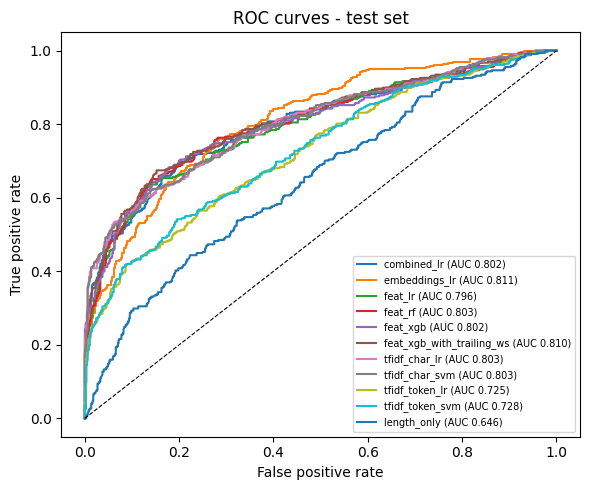

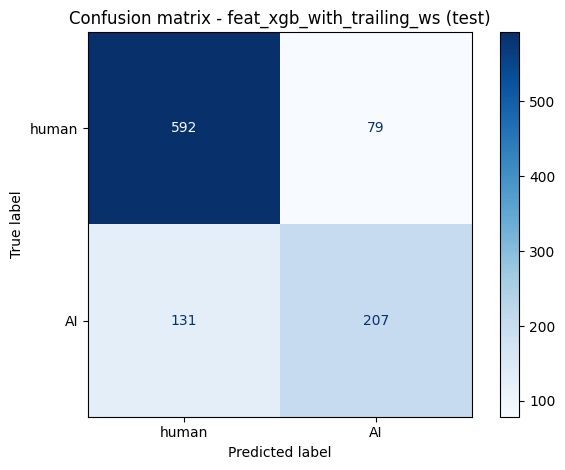

In [7]:
# ROC curves (test) and confusion matrix of the best model
plt.figure(figsize=(6, 5))
for name, t in test_frames.items():
    if name == "always_human":
        continue
    fpr, tpr, _ = roc_curve(t.y_true, t.y_score)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(t.y_true, t.y_score):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves - test set")
plt.legend(fontsize=7); plt.tight_layout()
plt.savefig(FINAL / "roc_curves.png", dpi=150); plt.show()

tb = test_frames[best]
cm = confusion_matrix(tb.y_true, tb.y_pred)
ConfusionMatrixDisplay(cm, display_labels=["human", "AI"]).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion matrix - {best} (test)"); plt.tight_layout()
plt.savefig(FINAL / "confusion_matrix.png", dpi=150); plt.show()

In [8]:
# Attach metadata (LLM, scenario, length) to the test predictions
extra_cols = [c for c in [LLM_COL, SCEN_COL, PROB_COL] if c]
mt = meta["test"].copy()
mt["sample_id"] = mt[ID_COL].astype(str)
mt["n_chars_eval"] = mt[CODE].astype(str).str.len()
mt = mt[["sample_id", "n_chars_eval", CODE] + extra_cols]

def attach(name):
    return test_frames[name].merge(mt, on="sample_id", how="left")

def recall_by(col):
    out = {}
    for name in test_frames:
        if name == "always_human":
            continue
        d = attach(name)
        ai = d[d.y_true == 1]
        out[name] = ai.assign(hit=(ai.y_pred == 1)).groupby(col)["hit"].mean()
    return pd.DataFrame(out).T.round(3)

if LLM_COL:
    per_llm = recall_by(LLM_COL)
    per_llm.to_csv(FINAL / "breakdown_per_llm.csv")
    print("AI recall per LLM (test):"); display(per_llm)
    print("AI samples per LLM:", attach(best).query("y_true == 1")[LLM_COL].value_counts().to_dict())
if SCEN_COL:
    per_scen = recall_by(SCEN_COL)
    per_scen.to_csv(FINAL / "breakdown_per_scenario.csv")
    print("AI recall per scenario (test):"); display(per_scen)

AI recall per LLM (test):


llm_name,codellama,codestral,gemini
combined_lr,0.829,0.725,0.544
embeddings_lr,0.841,0.794,0.576
feat_lr,0.878,0.748,0.536
feat_rf,0.866,0.710,0.480
feat_xgb,0.793,0.702,0.400
feat_xgb_with_trailing_ws,0.756,0.718,0.408
tfidf_char_lr,0.805,0.756,0.544
tfidf_char_svm,0.817,0.763,0.552
tfidf_token_lr,0.756,0.679,0.600
tfidf_token_svm,0.720,0.611,0.528


AI samples per LLM: {'codestral': 131, 'gemini': 125, 'codellama': 82}
AI recall per scenario (test):


scenario,fix_runtime_error,fix_wrong_answer,from_scratch
combined_lr,0.481,0.495,0.985
embeddings_lr,0.642,0.586,0.895
feat_lr,0.481,0.545,0.992
feat_rf,0.472,0.485,0.947
feat_xgb,0.406,0.394,0.940
feat_xgb_with_trailing_ws,0.415,0.394,0.932
tfidf_char_lr,0.500,0.525,0.962
tfidf_char_svm,0.509,0.535,0.970
tfidf_token_lr,0.472,0.545,0.917
tfidf_token_svm,0.396,0.455,0.887


In [9]:
# Accuracy by length bin (does length drive the result?)
d = attach(best)
d["length_bin"] = pd.qcut(d["n_chars_eval"], 5, duplicates="drop")
by_len = d.groupby("length_bin", observed=True).apply(
    lambda g: pd.Series({"n": len(g), "accuracy": (g.y_true == g.y_pred).mean(),
                         "ai_recall": ((g.y_pred == 1) & (g.y_true == 1)).sum() / max((g.y_true == 1).sum(), 1)}),
    include_groups=False).round(3)
by_len.to_csv(FINAL / "accuracy_by_length.csv")
print(f"Best model: {best}"); display(by_len)

Best model: feat_xgb_with_trailing_ws


,n,accuracy,ai_recall
length_bin,,,
"(55.999, 158.0]",203.0,0.754,0.559
"(158.0, 261.2]",201.0,0.776,0.638
"(261.2, 405.4]",201.0,0.811,0.766
"(405.4, 683.4]",202.0,0.767,0.514
"(683.4, 2913.0]",202.0,0.851,0.600


In [10]:
# Leakage checks
lines = []
if PROB_COL:
    ids = {s: set(meta[s][PROB_COL].astype(str)) for s in meta}
    for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
        lines.append(f"shared problem_ids {a}/{b}: {len(ids[a] & ids[b])}")
if "code_hash" in meta["train"].columns:
    hs = {s: set(meta[s]["code_hash"].astype(str)) for s in meta}
    for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
        lines.append(f"shared code_hash {a}/{b}: {len(hs[a] & hs[b])}")
else:
    lines.append("code_hash column not in split files: hash check skipped")
(FINAL / "leakage_check.txt").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines))

shared problem_ids train/val: 0
shared problem_ids train/test: 0
shared problem_ids val/test: 0
shared code_hash train/val: 0
shared code_hash train/test: 0
shared code_hash val/test: 0


In [11]:
# Error look: the most confident mistakes of the best model (2 AI called human, 3 human called AI)
d = attach(best)
ai_missed = d[(d.y_true == 1) & (d.y_pred == 0)].sort_values("y_score").head(2)
hu_flagged = d[(d.y_true == 0) & (d.y_pred == 1)].sort_values("y_score", ascending=False).head(3)
err = pd.concat([ai_missed.assign(error="AI called human"), hu_flagged.assign(error="human called AI")])
err["code_preview"] = err[CODE].astype(str).str.slice(0, 600)
err["why_guess"] = ""   # fill this in by hand: one line per example
keep = ["error", "sample_id", "y_score"] + [c for c in [LLM_COL, SCEN_COL] if c] + ["code_preview", "why_guess"]
err[keep].to_csv(FINAL / "error_examples.csv", index=False)
for _, r in err.iterrows():
    print("=" * 70); print(r["error"], "| score", round(r["y_score"], 3), "|", r.get(LLM_COL, ""), r.get(SCEN_COL, ""))
    print(r["code_preview"])

AI called human | score 0.035 | gemini fix_runtime_error
N, K = map(int, input().split())
X = list(map(int, input().split()))

# X.sort()

# print(X)

mi = 0
pl = 0

_mi = []
_pi = []

fl = 0
if X[0] < 0:
    for i in range(N):
        if X[i] >= 0:
            fl = i
            break

    # print(fl)

    _mi = X[:fl]
    _mi = _mi[::-1]

    for i in range(len(_mi)):
        _mi[i] = abs(_mi[i])

    _pi = X[fl:]

    # print(_mi)
    # print(_pi)


    ans = 10000000000000000

    l_mi = len(_mi)

    l_pi = len(_pi)

    for i in range(l_mi):
        if K - (i+1) <= l_pi and K - (i+1) >= 0:
            ans = min(ans, _mi[i]*2+_pi[(K-1)-(i+1)])

AI called human | score 0.048 | gemini fix_wrong_answer
import sys
import math
import itertools
import collections
from collections import deque
from collections import defaultdict

sys.setrecursionlimit(1000000)
MOD = 10 ** 9 + 7
input = lambda: sys.stdin.readline().strip()

NI = lambda: int(input())
NMI = lambda: map(int, input().split())

In [12]:
summary = {
    "best_model_on_validation": best,
    "thresholds_chosen_on_validation": {k: round(v, 5) for k, v in thr.items()},
    "test_metrics": comparison[["n_test", "test_acc", "test_precision", "test_recall", "test_f1", "test_auc"]].to_dict("index"),
    "validation_metrics": comparison[["n_val", "val_acc", "val_f1", "val_auc"]].to_dict("index"),
    "leakage_check": lines,
}
(FINAL / "final_results.json").write_text(json.dumps(summary, indent=2, default=float), encoding="utf-8")
print("saved results/final/final_results.json")
print([p.name for p in sorted(FINAL.iterdir())])

saved results/final/final_results.json
['.gitkeep', 'accuracy_by_length.csv', 'breakdown_per_llm.csv', 'breakdown_per_scenario.csv', 'comparison_table.csv', 'confusion_matrix.png', 'embedding_tuning.csv', 'error_examples.csv', 'final_results.json', 'leakage_check.txt', 'roc_curves.png']
